# 03 · Exploratory data analysis

Two halves:

1. **SQL**: the queries in [`sql/analysis.sql`](../sql/analysis.sql) run against `heart.db`, looking at disease risk by age group, sex, cholesterol range and chest-pain type.
2. **Charts** (Matplotlib): target balance, feature distributions, risk by group, and correlations. Figures are saved to `reports/figures/`.

Requires `python -m src.cleaning && python -m src.database` to have been run first.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

sys.path.append(str(Path.cwd().parent))
from src.cleaning import CLEAN_PATH, ENCODED_PATH
from src.queries import load_queries, run_query

pd.set_option("display.max_columns", None)
FIG_DIR = Path.cwd().parent / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## Part 1 · SQL queries

Each query in `analysis.sql` has a `-- name:` line; `run_query(name)` runs one and returns a DataFrame. "Risk" means the share of patients with heart disease.

In [2]:
list(load_queries())

['overall_disease_rate',
 'risk_by_age_group',
 'risk_by_sex',
 'risk_by_cholesterol_range',
 'risk_by_chest_pain_type',
 'risk_by_sex_and_chest_pain',
 'exercise_test_by_outcome',
 'risk_by_vessels_colored']

### 1. Baseline

In [3]:
run_query("overall_disease_rate")

,patients,with_disease,disease_pct
0,297,137,46.1


### 2. Risk by age group

In [4]:
run_query("risk_by_age_group")

,age_group,patients,with_disease,disease_pct
0,1) under 45,53,13,24.5
1,2) 45-54,85,29,34.1
2,3) 55-64,118,75,63.6
3,4) 65+,41,20,48.8


### 3. Risk by sex

In [5]:
run_query("risk_by_sex")

,sex,patients,with_disease,disease_pct
0,male,201,112,55.7
1,female,96,25,26.0


### 4. Risk by cholesterol range

Bands follow the NCEP ATP III guideline (desirable < 200, borderline 200–239, high ≥ 240 mg/dl).

In [6]:
run_query("risk_by_cholesterol_range")

,cholesterol_range,patients,avg_chol,disease_pct
0,1) desirable (<200),48,180.0,41.7
1,2) borderline (200-239),94,220.0,40.4
2,3) high (240+),155,285.0,51.0


### 5. Risk by chest-pain type

In [7]:
run_query("risk_by_chest_pain_type")

,chest_pain_type,patients,disease_pct
0,asymptomatic,142,72.5
1,typical_angina,23,30.4
2,non_anginal_pain,83,21.7
3,atypical_angina,49,18.4


### 6. Chest-pain type within each sex

In [8]:
run_query("risk_by_sex_and_chest_pain")

,sex,chest_pain_type,patients,disease_pct
0,female,asymptomatic,40,55.0
1,female,atypical_angina,18,11.1
2,female,non_anginal_pain,34,2.9
3,male,asymptomatic,102,79.4
4,male,typical_angina,19,36.8
5,male,non_anginal_pain,49,34.7
6,male,atypical_angina,31,22.6


### 7. Exercise-test results by outcome

In [9]:
run_query("exercise_test_by_outcome")

,outcome,patients,avg_max_heart_rate,avg_st_depression,exercise_angina_pct,avg_vessels_colored
0,no disease,160,158.6,0.60,14.4,0.28
1,disease,137,139.1,1.59,54.0,1.15


### 8. Risk by number of vessels colored

In [10]:
run_query("risk_by_vessels_colored")

,vessels_colored,patients,disease_pct
0,0,174,25.9
1,1,65,67.7
2,2,38,81.6
3,3,20,85.0


## Part 2 · Charts

One shared style: blue = no disease, orange = disease (a colorblind-safe pair), light gridlines, labels in gray ink rather than series colors.

In [11]:
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
NO_DISEASE, DISEASE = "#2a78d6", "#eb6834"
OUTCOME_LEGEND = [Patch(color=NO_DISEASE, label="No disease"), Patch(color=DISEASE, label="Disease")]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

df = pd.read_csv(CLEAN_PATH)

### Target balance

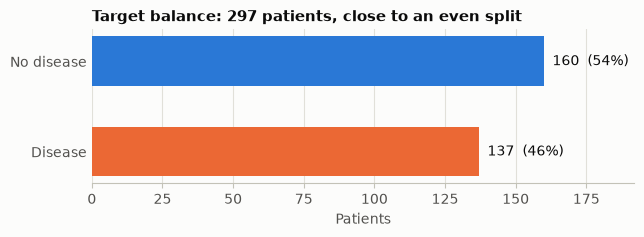

In [12]:
counts = df["target"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 2))
bars = ax.barh(["No disease", "Disease"], counts.values, color=[NO_DISEASE, DISEASE], height=0.55)
ax.invert_yaxis()
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height() / 2,
            f"{n}  ({n / len(df):.0%})", va="center", color=INK)
ax.set_xlim(0, counts.max() * 1.2)
ax.set_xlabel("Patients")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title(f"Target balance: {len(df)} patients, close to an even split")
save(fig, "01_target_balance")
plt.show()

### Distributions by outcome

Step outlines instead of filled bars so the two groups can overlap without hiding each other.

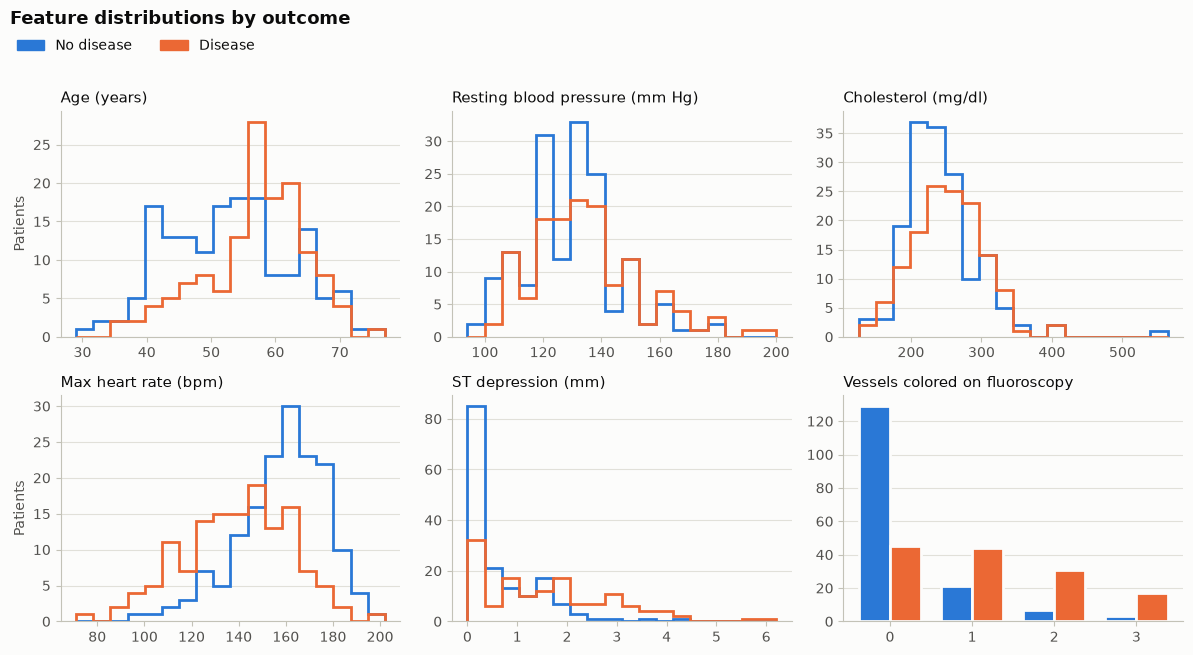

In [13]:
features = {
    "age": "Age (years)",
    "trestbps": "Resting blood pressure (mm Hg)",
    "chol": "Cholesterol (mg/dl)",
    "thalach": "Max heart rate (bpm)",
    "oldpeak": "ST depression (mm)",
    "ca": "Vessels colored on fluoroscopy",
}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for i, (ax, (col, label)) in enumerate(zip(axes.flat, features.items())):
    groups = [(df.loc[df["target"] == t, col], color) for t, color in [(0, NO_DISEASE), (1, DISEASE)]]
    if col == "ca":
        tab = pd.crosstab(df["ca"], df["target"])
        x, w = np.arange(len(tab)), 0.38
        ax.bar(x - w / 2, tab[0], w, color=NO_DISEASE, edgecolor=SURFACE, linewidth=2)
        ax.bar(x + w / 2, tab[1], w, color=DISEASE, edgecolor=SURFACE, linewidth=2)
        ax.set_xticks(x, tab.index)
    else:
        bins = np.histogram_bin_edges(df[col], bins=18)
        for values, color in groups:
            ax.hist(values, bins=bins, histtype="step", linewidth=2, color=color)
    ax.set_title(label, fontweight="normal", color=INK)
    ax.grid(axis="x", visible=False)
    if i % 3 == 0:
        ax.set_ylabel("Patients")
fig.suptitle("Feature distributions by outcome", x=0.01, y=1.0, ha="left", fontweight="bold", fontsize=13)
fig.legend(handles=OUTCOME_LEGEND, loc="upper left", ncol=2, bbox_to_anchor=(0.005, 0.975))
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "02_distributions")
plt.show()

### Risk by group (from the SQL queries)

The four requested breakdowns, drawn straight from the query results. The dashed line is the overall rate.

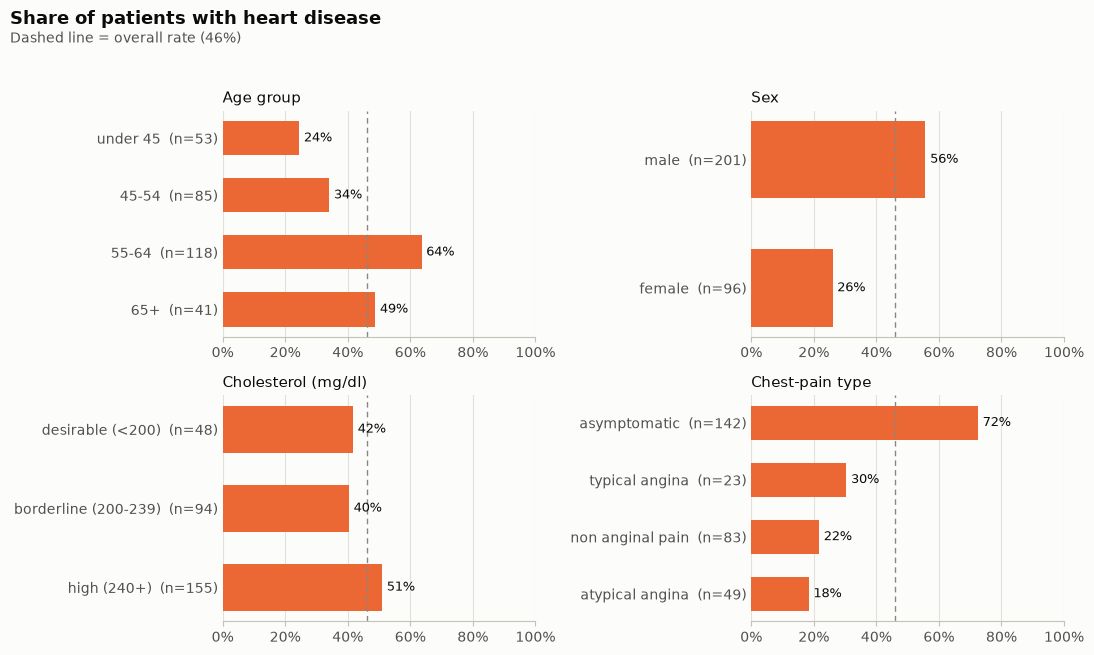

In [14]:
overall = run_query("overall_disease_rate")["disease_pct"].iloc[0]
panels = [
    ("risk_by_age_group", "age_group", "Age group"),
    ("risk_by_sex", "sex", "Sex"),
    ("risk_by_cholesterol_range", "cholesterol_range", "Cholesterol (mg/dl)"),
    ("risk_by_chest_pain_type", "chest_pain_type", "Chest-pain type"),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, (query, col, title) in zip(axes.flat, panels):
    r = run_query(query)
    names = r[col].str.replace(r"^\d\) ", "", regex=True).str.replace("_", " ")
    labels = [f"{name}  (n={n})" for name, n in zip(names, r["patients"])]
    ax.barh(labels, r["disease_pct"], color=DISEASE, height=0.6)
    ax.invert_yaxis()
    for y, v in enumerate(r["disease_pct"]):
        ax.text(v + 1.5, y, f"{v:.0f}%", va="center", color=INK, fontsize=9)
    ax.axvline(overall, color=MUTED, linestyle=(0, (4, 3)), linewidth=1)
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter())
    ax.set_title(title, fontweight="normal", color=INK)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
fig.suptitle("Share of patients with heart disease", x=0.01, y=1.0, ha="left", fontweight="bold", fontsize=13)
fig.text(0.01, 0.95, f"Dashed line = overall rate ({overall:.0f}%)", color=INK_2, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "03_risk_by_group")
plt.show()

### Correlation heatmap

Uses the one-hot encoded file: correlating raw category codes (e.g. `thal` = 3/6/7) would be meaningless. Blue = negative, red = positive, gray = none. Only the lower triangle is shown (the matrix is symmetric), and only correlations with |r| ≥ 0.4 are labelled.

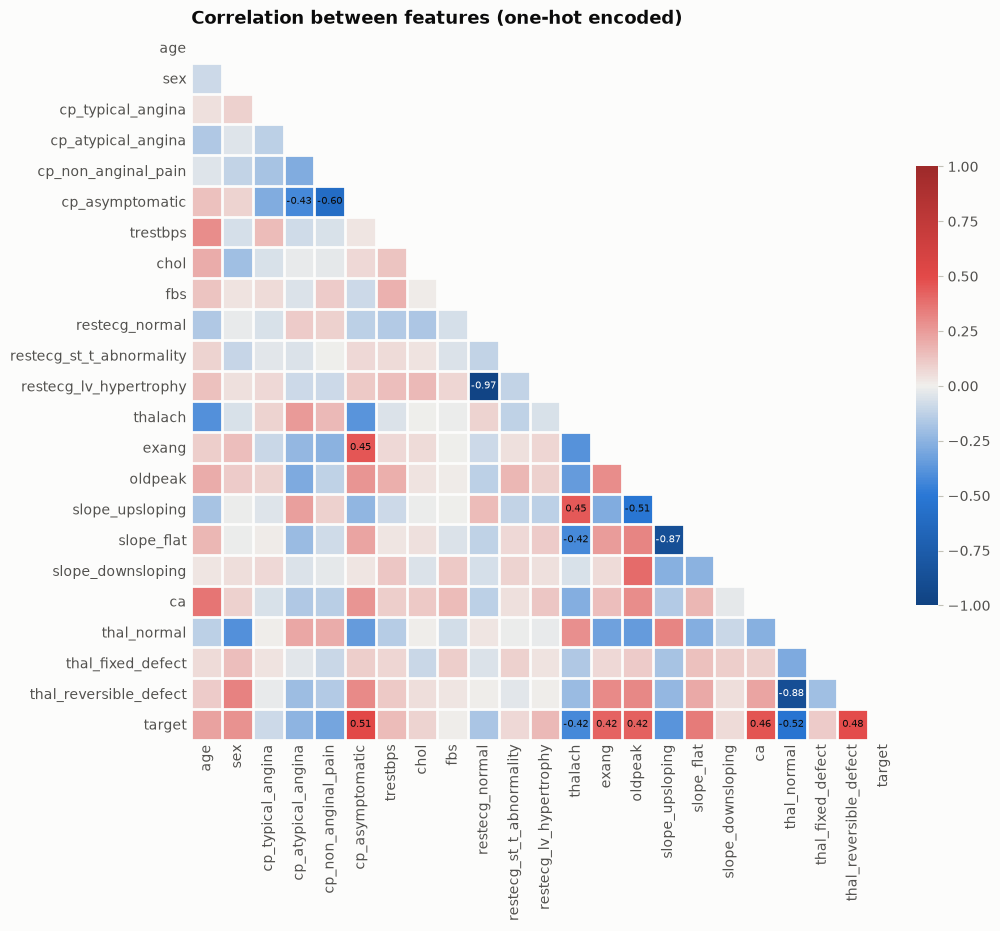

In [15]:
encoded = pd.read_csv(ENCODED_PATH).drop(columns=["patient_id"])
corr = encoded.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

diverging = LinearSegmentedColormap.from_list(
    "blue_gray_red", ["#104281", "#2a78d6", "#f0efec", "#e34948", "#9e2a2a"])
diverging.set_bad(SURFACE)

n = len(corr)
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(corr.mask(mask), cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(n), corr.columns, rotation=90)
ax.set_yticks(range(n), corr.columns)
ax.set_xticks(np.arange(-0.5, n), minor=True)
ax.set_yticks(np.arange(-0.5, n), minor=True)
ax.grid(False)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="both", length=0)
for side in ax.spines.values():
    side.set_visible(False)
for i in range(n):
    for j in range(i):
        r = corr.iat[i, j]
        if abs(r) >= 0.4:
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7,
                    color="#ffffff" if abs(r) >= 0.6 else INK)
cbar = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.02)
cbar.outline.set_visible(False)
cbar.ax.tick_params(color=AXIS, labelcolor=INK_2)
ax.set_title("Correlation between features (one-hot encoded)", fontsize=13)
save(fig, "04_correlation_heatmap")
plt.show()

### Which features move with the target?

The heatmap's `target` row, sorted. This is a first, one-feature-at-a-time view; the models in later weeks will test which features still matter when combined.

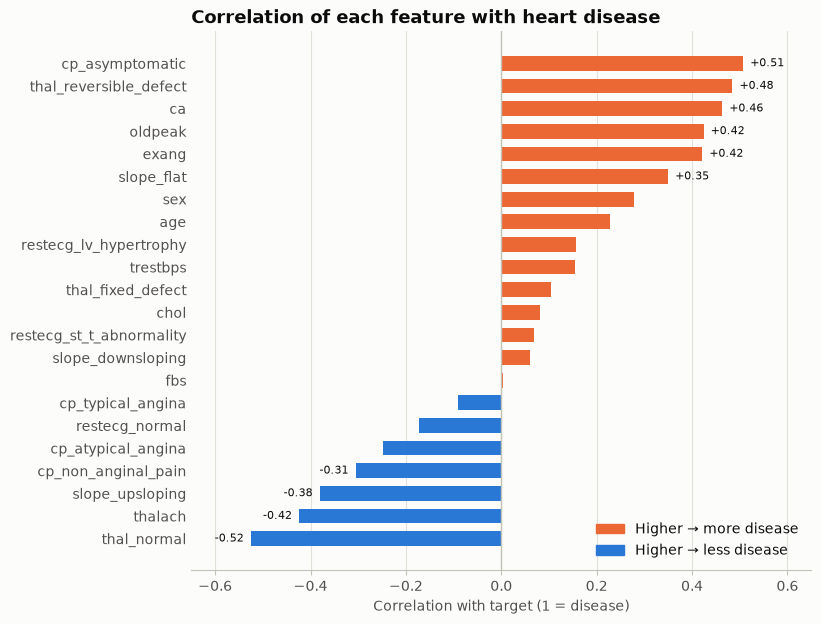

In [16]:
target_corr = corr["target"].drop("target").sort_values()
colors = [DISEASE if r > 0 else NO_DISEASE for r in target_corr]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(target_corr.index, target_corr.values, color=colors, height=0.65)
ax.axvline(0, color=AXIS, linewidth=1)
for y, r in enumerate(target_corr.values):
    if abs(r) >= 0.3:
        ax.text(r + (0.015 if r > 0 else -0.015), y, f"{r:+.2f}", va="center",
                ha="left" if r > 0 else "right", fontsize=8, color=INK)
ax.set_xlim(-0.65, 0.65)
ax.set_xlabel("Correlation with target (1 = disease)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.legend(handles=[Patch(color=DISEASE, label="Higher → more disease"),
                   Patch(color=NO_DISEASE, label="Higher → less disease")], loc="lower right")
ax.set_title("Correlation of each feature with heart disease", fontsize=13)
save(fig, "05_target_correlations")
plt.show()

In [17]:
target_corr.sort_values(key=abs, ascending=False).head(8).round(2)

thal_normal              -0.52
cp_asymptomatic           0.51
thal_reversible_defect    0.48
ca                        0.46
oldpeak                   0.42
thalach                  -0.42
exang                     0.42
slope_upsloping          -0.38
Name: target, dtype: float64

## Findings

*(Numbers come from the SQL results and charts above.)*

1. **"Asymptomatic" chest pain is the strongest single signal.** 72.5% of asymptomatic patients have disease, vs. 18–30% for the three types of chest pain (r = +0.51). It holds for both sexes (79% of men, 55% of women). This is less strange than it sounds: everyone here was referred for angiography, so "asymptomatic" means silent disease found for another reason.
2. **Exercise-test results separate the groups clearly.** Patients with disease reach a lower max heart rate (139 vs. 159 bpm), show more ST depression (1.59 vs. 0.60 mm) and have exercise-induced angina far more often (54% vs. 14%).
3. **Risk climbs with each blocked vessel.** 26% with 0 vessels colored → 68% → 82% → 85% with 3. A normal thallium test is the strongest *protective* signal (r = −0.52).
4. **Men and patients aged 55–64 carry more risk.** 56% of men vs. 26% of women. Risk rises from 24% (under 45) to 64% (55–64), then dips to 49% at 65+ (only 41 patients, so treat with caution).
5. **Cholesterol is a weak signal on its own.** 42% / 40% / 51% for desirable / borderline / high, and r = +0.08 overall, despite its reputation.

**Caveats:** these are one-feature-at-a-time views on a small (297), referred hospital cohort, not the general population. Several signals overlap (e.g. `thalach` and `slope_upsloping`, r = 0.45), which the models in later weeks will need to handle.

**Next (Week 4):** baseline models with accuracy, recall and ROC-AUC.